In [1]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
train_df = pd.read_excel("../data/Data_Train.xlsx")
test_df = pd.read_excel("../data/Test_set.xlsx")
sample_df = pd.read_excel("../data/Sample_submission.xlsx")

print("Training Data:", train_df.shape)
print("Testing Data:", test_df.shape)
print("Sample Submission:", sample_df.shape)

Training Data: (10683, 11)
Testing Data: (2671, 10)
Sample Submission: (2671, 1)


In [3]:
# Training dataset information
print("TRAINING DATA INFO")
train_df.info()

print("\nMISSING VALUES")
print(train_df.isnull().sum())

print("\nDUPLICATE ROWS")
print(train_df.duplicated().sum())

print("\nFIRST 5 ROWS")
display(train_df.head())

print("\nBOTTOM 5 ROWS")
display(train_df.tail())

TRAINING DATA INFO
<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Date_of_Journey  10683 non-null  str  
 2   Source           10683 non-null  str  
 3   Destination      10683 non-null  str  
 4   Route            10682 non-null  str  
 5   Dep_Time         10683 non-null  str  
 6   Arrival_Time     10683 non-null  str  
 7   Duration         10683 non-null  str  
 8   Total_Stops      10682 non-null  str  
 9   Additional_Info  10683 non-null  str  
 10  Price            10683 non-null  int64
dtypes: int64(1), str(10)
memory usage: 1.8 MB

MISSING VALUES
Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

DUP

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302



BOTTOM 5 ROWS


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648
10682,Air India,9/05/2019,Delhi,Cochin,DEL → GOI → BOM → COK,10:55,19:15,8h 20m,2 stops,No info,11753


In [4]:
# Check rows having missing values
missing_rows = train_df[train_df.isnull().any(axis=1)]

print("Rows with missing values:")
display(missing_rows)

# Check duplicate records
duplicate_rows = train_df[train_df.duplicated(keep=False)]

print("Total duplicate records:", len(duplicate_rows))
display(duplicate_rows.head(10))

Rows with missing values:


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
9039,Air India,6/05/2019,Delhi,Cochin,NaN,09:45,09:25 07 May,23h 40m,NaN,No info,7480


Total duplicate records: 415


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
33,Jet Airways,15/06/2019,Delhi,Cochin,DEL → NAG → BOM → COK,14:35,12:35 16 Jun,22h,2 stops,In-flight meal not included,10919
49,Jet Airways,27/06/2019,Delhi,Cochin,DEL → AMD → BOM → COK,23:05,19:00 28 Jun,19h 55m,2 stops,In-flight meal not included,11150
73,Jet Airways,24/06/2019,Delhi,Cochin,DEL → AMD → BOM → COK,23:05,12:35 25 Jun,13h 30m,2 stops,No info,12819
81,Jet Airways,24/03/2019,Banglore,New Delhi,BLR → DEL,19:55,22:35,2h 40m,non-stop,No info,7229
87,Jet Airways,6/06/2019,Delhi,Cochin,DEL → JAI → BOM → COK,09:40,04:25 07 Jun,18h 45m,2 stops,No info,13014
136,Jet Airways,6/06/2019,Delhi,Cochin,DEL → NAG → BOM → COK,06:45,04:25 07 Jun,21h 40m,2 stops,No info,13376
137,Air India,27/06/2019,Delhi,Cochin,DEL → GOI → BOM → COK,22:00,19:15 28 Jun,21h 15m,2 stops,No info,10441
209,Jet Airways,18/05/2019,Delhi,Cochin,DEL → AMD → BOM → COK,23:05,04:25 20 May,29h 20m,2 stops,No info,15129
224,Jet Airways,9/06/2019,Delhi,Cochin,DEL → JAI → BOM → COK,05:30,04:25 10 Jun,22h 55m,2 stops,No info,13014
251,Air India,1/06/2019,Delhi,Cochin,DEL → AMD → BOM → COK,19:45,19:15 02 Jun,23h 30m,2 stops,No info,10651


In [5]:
# Create a copy of original training data
train_clean = train_df.copy()

# Remove exact duplicate rows
train_clean = train_clean.drop_duplicates()

# Remove rows with missing Route and Total_Stops
train_clean = train_clean.dropna(
    subset=["Route", "Total_Stops"]
)

print("Original Shape:", train_df.shape)
print("Cleaned Shape:", train_clean.shape)

print("\nRemaining Missing Values:")
print(train_clean.isnull().sum().sum())

print("\nRemaining Duplicate Rows:")
print(train_clean.duplicated().sum())

Original Shape: (10683, 11)
Cleaned Shape: (10462, 11)

Remaining Missing Values:
0

Remaining Duplicate Rows:
0


In [6]:
# Separate categorical and numerical columns

categorical_cols = train_clean.select_dtypes(
    include="object"
).columns.tolist()

numerical_cols = train_clean.select_dtypes(
    include="number"
).columns.tolist()

print("Categorical Columns:")
print(categorical_cols)

print("\nNumerical Columns:")
print(numerical_cols)

print("\nUnique Values in Each Categorical Column:")
for col in categorical_cols:
    print(col, ":", train_clean[col].nunique())

Categorical Columns:
['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route', 'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops', 'Additional_Info']

Numerical Columns:
['Price']

Unique Values in Each Categorical Column:
Airline : 12
Date_of_Journey : 44
Source : 5
Destination : 6
Route : 128
Dep_Time : 222
Arrival_Time : 1343
Duration : 368
Total_Stops : 5
Additional_Info : 10


C:\Users\Mrinal Dutta\AppData\Local\Temp\ipykernel_16980\2080065055.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_clean.select_dtypes(


In [7]:
# Convert Date_of_Journey into datetime
train_clean["Date_of_Journey"] = pd.to_datetime(
    train_clean["Date_of_Journey"],
    dayfirst=True
)

# Extract Day and Month
train_clean["Journey_Day"] = train_clean["Date_of_Journey"].dt.day
train_clean["Journey_Month"] = train_clean["Date_of_Journey"].dt.month

# Check results
display(train_clean[[
    "Date_of_Journey",
    "Journey_Day",
    "Journey_Month"
]].head())

print(train_clean[["Journey_Day", "Journey_Month"]].dtypes)

,Date_of_Journey,Journey_Day,Journey_Month
0,2019-03-24,24,3
1,2019-05-01,1,5
2,2019-06-09,9,6
3,2019-05-12,12,5
4,2019-03-01,1,3


Journey_Day      int32
Journey_Month    int32
dtype: object


In [8]:
# Extract departure hour and minute

train_clean["Dep_Hour"] = pd.to_datetime(
    train_clean["Dep_Time"], format="%H:%M"
).dt.hour

train_clean["Dep_Minute"] = pd.to_datetime(
    train_clean["Dep_Time"], format="%H:%M"
).dt.minute

# Check results
display(train_clean[[
    "Dep_Time",
    "Dep_Hour",
    "Dep_Minute"
]].head())

,Dep_Time,Dep_Hour,Dep_Minute
0,22:20,22,20
1,05:50,5,50
2,09:25,9,25
3,18:05,18,5
4,16:50,16,50


In [9]:
# Extract arrival hour and minute

train_clean["Arrival_Hour"] = pd.to_datetime(
    train_clean["Arrival_Time"].str.split().str[0],
    format="%H:%M"
).dt.hour

train_clean["Arrival_Minute"] = pd.to_datetime(
    train_clean["Arrival_Time"].str.split().str[0],
    format="%H:%M"
).dt.minute

# Check results
display(train_clean[[
    "Arrival_Time",
    "Arrival_Hour",
    "Arrival_Minute"
]].head())

,Arrival_Time,Arrival_Hour,Arrival_Minute
0,01:10 22 Mar,1,10
1,13:15,13,15
2,04:25 10 Jun,4,25
3,23:30,23,30
4,21:35,21,35


In [10]:
# Extract hours and minutes from Duration

duration_split = train_clean["Duration"].str.extract(
    r"(?:(\d+)h)?\s*(?:(\d+)m)?"
)

hours = duration_split[0].fillna(0).astype(int)
minutes = duration_split[1].fillna(0).astype(int)

# Convert duration into total hours
train_clean["Duration_Hours"] = hours + (minutes / 60)

# Check results
display(train_clean[[
    "Duration",
    "Duration_Hours"
]].head(10))

,Duration,Duration_Hours
0,2h 50m,2.833333
1,7h 25m,7.416667
2,19h,19.000000
3,5h 25m,5.416667
4,4h 45m,4.750000
5,2h 25m,2.416667
6,15h 30m,15.500000
7,21h 5m,21.083333
8,25h 30m,25.500000
9,7h 50m,7.833333


In [11]:
hours

0         2
1         7
2        19
3         5
4         4
         ..
10678     2
10679     2
10680     3
10681     2
10682     8
Name: 0, Length: 10462, dtype: int64

In [12]:
minutes

0        50
1        25
2         0
3        25
4        45
         ..
10678    30
10679    35
10680     0
10681    40
10682    20
Name: 1, Length: 10462, dtype: int64

In [13]:
duration_split

,0,1
0,2,50
1,7,25
2,19,NaN
3,5,25
4,4,45
...,...,...
10678,2,30
10679,2,35
10680,3,NaN
10681,2,40


In [14]:
print(train_clean["Total_Stops"].value_counts())

Total_Stops
1 stop      5625
non-stop    3475
2 stops     1318
3 stops       43
4 stops        1
Name: count, dtype: int64


In [15]:
stops_mapping = {
    "non-stop": 0,
    "1 stop": 1,
    "2 stops": 2,
    "3 stops": 3,
    "4 stops": 4
}

train_clean["Total_Stops"] = train_clean["Total_Stops"].map(stops_mapping)

display(train_clean[["Total_Stops"]].head(10))

,Total_Stops
0,0
1,2
2,2
3,1
4,1
5,0
6,1
7,1
8,1
9,1


In [16]:
print("Unique Routes:", train_clean["Route"].nunique())
display(train_clean["Route"].value_counts().head(10))

Unique Routes: 128


Route
DEL → BOM → COK    2376
BLR → DEL          1536
CCU → BOM → BLR     979
CCU → BLR           724
BOM → HYD           621
CCU → DEL → BLR     565
BLR → BOM → DEL     402
MAA → CCU           381
DEL → HYD → COK     326
DEL → BLR → COK     232
Name: count, dtype: int64

In [17]:
train_clean.drop(columns=["Route"], inplace=True)

print("Route column removed successfully!")
print(train_clean.shape)

Route column removed successfully!
(10462, 17)


In [18]:
print(train_clean["Additional_Info"].value_counts())

Additional_Info
No info                         8182
In-flight meal not included     1926
No check-in baggage included     318
1 Long layover                    19
Change airports                    7
Business class                     4
No Info                            3
1 Short layover                    1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64


In [19]:
train_clean.drop(columns=["Additional_Info"], inplace=True)

print("Additional_Info column removed!")
print(train_clean.shape)

Additional_Info column removed!
(10462, 16)


In [20]:
train_clean.drop(
    columns=[
        "Date_of_Journey",
        "Dep_Time",
        "Arrival_Time",
        "Duration"
    ],
    inplace=True
)

print("Original columns removed successfully!")
print(train_clean.shape)

Original columns removed successfully!
(10462, 12)


In [21]:
categorical_cols = train_clean.select_dtypes(
    include=["object"]
).columns.tolist()

print("Categorical Columns:")
print(categorical_cols)

print("\nTotal Categorical Columns:", len(categorical_cols))

Categorical Columns:
['Airline', 'Source', 'Destination']

Total Categorical Columns: 3


C:\Users\Mrinal Dutta\AppData\Local\Temp\ipykernel_16980\1493993536.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_clean.select_dtypes(


In [22]:
for col in categorical_cols:
    print(f"\n{col}")
    print("Unique Values:", train_clean[col].nunique())
    print(train_clean[col].unique())


Airline
Unique Values: 12
<ArrowStringArray>
[                           'IndiGo',                         'Air India',
                       'Jet Airways',                          'SpiceJet',
                 'Multiple carriers',                             'GoAir',
                           'Vistara',                          'Air Asia',
           'Vistara Premium economy',              'Jet Airways Business',
 'Multiple carriers Premium economy',                            'Trujet']
Length: 12, dtype: str

Source
Unique Values: 5
<ArrowStringArray>
['Banglore', 'Kolkata', 'Delhi', 'Chennai', 'Mumbai']
Length: 5, dtype: str

Destination
Unique Values: 6
<ArrowStringArray>
['New Delhi', 'Banglore', 'Cochin', 'Kolkata', 'Delhi', 'Hyderabad']
Length: 6, dtype: str


In [23]:
numerical_cols = train_clean.select_dtypes(
    include=["number"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

print("\nTotal Numerical Columns:", len(numerical_cols))

Numerical Columns:
['Total_Stops', 'Price', 'Journey_Day', 'Journey_Month', 'Dep_Hour', 'Dep_Minute', 'Arrival_Hour', 'Arrival_Minute', 'Duration_Hours']

Total Numerical Columns: 9


In [24]:
train_clean[numerical_cols].describe().round(2)

,Total_Stops,Price,Journey_Day,Journey_Month,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Hours
count,10462.00,10462.00,10462.00,10462.00,10462.00,10462.00,10462.00,10462.00,10462.00
mean,0.80,9026.79,13.46,4.70,12.48,24.40,13.39,24.72,10.50
std,0.66,4624.85,8.47,1.16,5.73,18.82,6.86,16.57,8.34
min,0.00,1759.00,1.00,3.00,0.00,0.00,0.00,0.00,0.08
25%,0.00,5224.00,6.00,3.00,8.00,5.00,8.00,10.00,2.83
50%,1.00,8266.00,12.00,5.00,11.00,25.00,14.00,25.00,8.42
75%,1.00,12344.75,21.00,6.00,18.00,40.00,19.00,35.00,15.17
max,4.00,79512.00,27.00,6.00,23.00,55.00,23.00,55.00,47.67


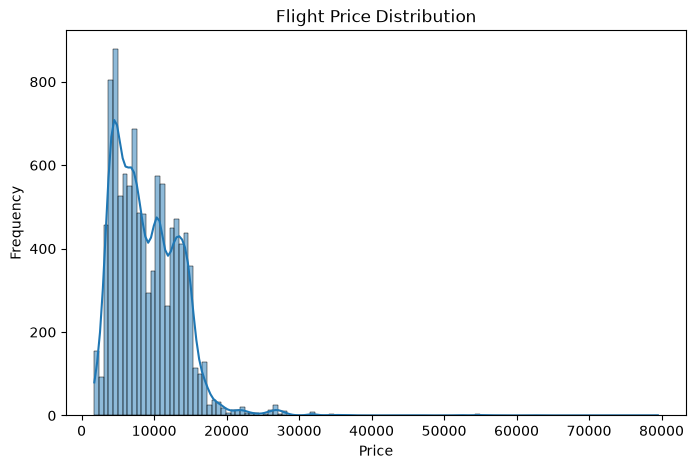

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(train_clean["Price"], kde=True)

plt.title("Flight Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

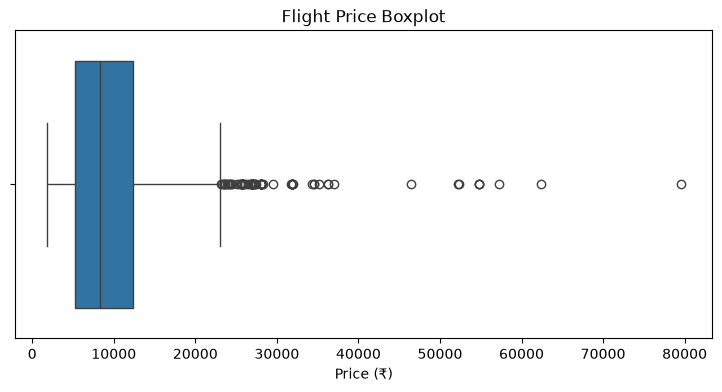

In [26]:
plt.figure(figsize=(9, 4))

sns.boxplot(x=train_clean["Price"])

plt.title("Flight Price Boxplot")
plt.xlabel("Price (₹)")

plt.show()

In [27]:
Q1 = train_clean["Price"].quantile(0.25)
Q3 = train_clean["Price"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 5224.0
Q3: 12344.75
IQR: 7120.75
Lower Limit: -5457.125
Upper Limit: 23025.875


In [28]:
outliers = train_clean[
    train_clean["Price"] > upper_limit
]

print("Total Outliers:", len(outliers))
print("Outlier Percentage:",
      round(len(outliers) / len(train_clean) * 100, 2), "%")

Total Outliers: 94
Outlier Percentage: 0.9 %


In [29]:
display(
    outliers[[
        "Airline",
        "Source",
        "Destination",
        "Total_Stops",
        "Duration_Hours",
        "Price"
    ]].sort_values(by="Price", ascending=False).head(10)
)

,Airline,Source,Destination,Total_Stops,Duration_Hours,Price
2924,Jet Airways Business,Banglore,New Delhi,1,5.666667,79512
5372,Jet Airways Business,Banglore,New Delhi,1,6.666667,62427
10364,Jet Airways Business,Banglore,New Delhi,1,4.666667,57209
5439,Jet Airways,Banglore,New Delhi,1,6.083333,54826
2618,Jet Airways,Banglore,New Delhi,1,6.250000,54826
1478,Jet Airways,Banglore,New Delhi,1,6.083333,54826
9715,Jet Airways Business,Delhi,Cochin,2,8.333333,52285
657,Jet Airways Business,Banglore,New Delhi,1,5.000000,52229
7351,Jet Airways Business,Delhi,Cochin,2,8.333333,46490
396,Multiple carriers,Delhi,Cochin,1,6.416667,36983


In [30]:
print("Missing Values:")
print(train_clean.isnull().sum())

Missing Values:
Airline           0
Source            0
Destination       0
Total_Stops       0
Price             0
Journey_Day       0
Journey_Month     0
Dep_Hour          0
Dep_Minute        0
Arrival_Hour      0
Arrival_Minute    0
Duration_Hours    0
dtype: int64


In [31]:
print("Total Duplicate Rows:", train_clean.duplicated().sum())

Total Duplicate Rows: 2


In [32]:
duplicate_rows = train_clean[
    train_clean.duplicated(keep=False)
]

display(duplicate_rows)

,Airline,Source,Destination,Total_Stops,Price,Journey_Day,Journey_Month,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Hours
1021,Air Asia,Banglore,New Delhi,0,4482,24,3,23,25,2,10,2.750000
5369,Vistara,Banglore,New Delhi,0,7608,3,3,21,10,0,5,2.916667
6805,Vistara,Banglore,New Delhi,0,7608,3,3,21,10,0,5,2.916667
8733,Air Asia,Banglore,New Delhi,0,4482,24,3,23,25,2,10,2.750000


In [33]:
train_encoded = pd.get_dummies(
    train_clean,
    columns=["Airline", "Source", "Destination"],
    drop_first=True,
    dtype=int
)

print("Before Encoding:", train_clean.shape)
print("After Encoding:", train_encoded.shape)

display(train_encoded.head())

Before Encoding: (10462, 12)
After Encoding: (10462, 29)


,Total_Stops,Price,Journey_Day,Journey_Month,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Hours,Airline_Air India,...,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,3897,24,3,22,20,1,10,2.833333,0,...,0,0,0,0,0,0,0,0,0,1
1,2,7662,1,5,5,50,13,15,7.416667,1,...,0,0,0,1,0,0,0,0,0,0
2,2,13882,9,6,9,25,4,25,19.000000,0,...,0,0,1,0,0,1,0,0,0,0
3,1,6218,12,5,18,5,23,30,5.416667,0,...,0,0,0,1,0,0,0,0,0,0
4,1,13302,1,3,16,50,21,35,4.750000,0,...,0,0,0,0,0,0,0,0,0,1


In [34]:
X = train_encoded.drop("Price", axis=1)
y = train_encoded["Price"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (10462, 28)
Target Shape: (10462,)


In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8369, 28)
X_test: (2093, 28)
y_train: (8369,)
y_test: (2093,)


In [36]:
from sklearn.preprocessing import StandardScaler

# Numerical columns
num_cols = X_train.select_dtypes(include=np.number).columns

# Create scaler
scaler = StandardScaler()

# Fit on training data and transform
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])

# Transform testing data
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("Feature Scaling Completed!")

Feature Scaling Completed!


In [37]:
from sklearn.linear_model import LinearRegression

# Create model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [38]:
# Predict prices
y_pred = lr_model.predict(X_test)

# Compare actual and predicted prices
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

display(comparison.head(10))

,Actual Price,Predicted Price
0,17996,14546.186619
1,3873,4536.303684
2,4462,4779.974836
3,2228,7085.112503
4,4991,2525.640410
5,7670,10427.703736
6,14086,12290.040451
7,6386,6995.779511
8,6628,8010.928008
9,6934,5591.003191


In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 1998.6393059377112
RMSE: 2945.796235704494
R2 Score: 0.5838081325633981


In [40]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=2
)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [41]:
# Predict flight prices
rf_pred = rf_model.predict(X_test)

# Compare actual and predicted prices
rf_comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": rf_pred
})

display(rf_comparison.head(10))

,Actual Price,Predicted Price
0,17996,14698.782214
1,3873,3862.266920
2,4462,4259.456305
3,2228,4550.310667
4,4991,4260.725711
5,7670,7797.200148
6,14086,14609.810027
7,6386,6364.799462
8,6628,6244.807165
9,6934,6526.859857


In [42]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2 Score:", rf_r2)

Random Forest MAE: 1112.8980365885698
Random Forest RMSE: 1843.7370226671358
Random Forest R2 Score: 0.8369630144396888


In [43]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

print("Gradient Boosting Model Trained Successfully!")

Gradient Boosting Model Trained Successfully!


In [44]:
# Predict flight prices
gb_pred = gb_model.predict(X_test)

# Compare actual and predicted prices
gb_comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": gb_pred
})

display(gb_comparison.head(10))

,Actual Price,Predicted Price
0,17996,15563.005815
1,3873,4225.574884
2,4462,5176.527720
3,2228,5111.328992
4,4991,4088.550182
5,7670,9993.983228
6,14086,11947.343362
7,6386,7393.327340
8,6628,7646.362825
9,6934,5359.183108


In [45]:
gb_mae = mean_absolute_error(y_test, gb_pred)
gb_mse = mean_squared_error(y_test, gb_pred)
gb_rmse = np.sqrt(gb_mse)
gb_r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting MAE:", gb_mae)
print("Gradient Boosting RMSE:", gb_rmse)
print("Gradient Boosting R2 Score:", gb_r2)

Gradient Boosting MAE: 1644.0517663771689
Gradient Boosting RMSE: 2394.639603875838
Gradient Boosting R2 Score: 0.7249773226734563


In [46]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae,
        rf_mae,
        gb_mae
    ],
    "RMSE": [
        rmse,
        rf_rmse,
        gb_rmse
    ],
    "R2 Score": [
        r2,
        rf_r2,
        gb_r2
    ]
})

display(model_comparison.sort_values(by="R2 Score", ascending=False))

,Model,MAE,RMSE,R2 Score
1,Random Forest,1112.898037,1843.737023,0.836963
2,Gradient Boosting,1644.051766,2394.639604,0.724977
0,Linear Regression,1998.639306,2945.796236,0.583808


In [47]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
7,Duration_Hours,0.474989
1,Journey_Day,0.128296
12,Airline_Jet Airways Business,0.069794
11,Airline_Jet Airways,0.062285
2,Journey_Month,0.056800
5,Arrival_Hour,0.031619
0,Total_Stops,0.030073
3,Dep_Hour,0.023086
4,Dep_Minute,0.022885
27,Destination_New Delhi,0.022669


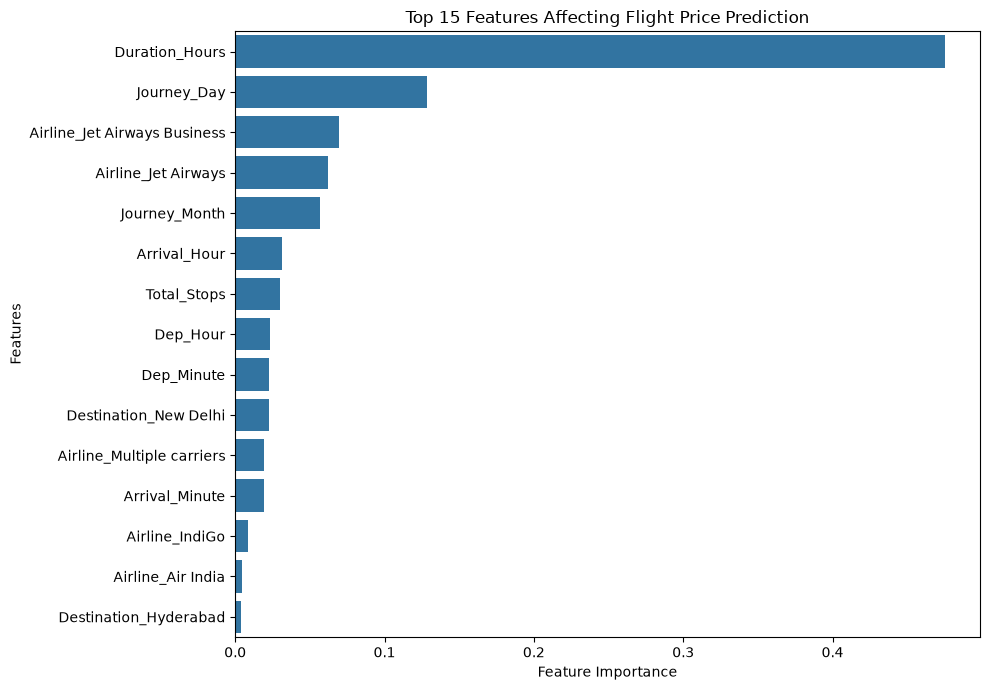

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Affecting Flight Price Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [49]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "n_estimators": [100, 150, 200],
    "max_depth": [10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.7]
}

print("Hyperparameter search space ready!")

Hyperparameter search space ready!


In [50]:
rf_random = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring="r2",
    random_state=42,
    n_jobs=2,
    verbose=1
)

print("Randomized Search is ready!")

Randomized Search is ready!


In [51]:
rf_random.fit(X_train, y_train)

print("Hyperparameter Tuning Completed!")

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Hyperparameter Tuning Completed!


In [52]:
print("Best Parameters:")
print(rf_random.best_params_)

print("\nBest Cross Validation R2 Score:")
print(rf_random.best_score_)

Best Parameters:
{'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 20}

Best Cross Validation R2 Score:
0.8221934778242345


In [53]:
# Get the best tuned model
best_rf_model = rf_random.best_estimator_

# Predict on test data
tuned_pred = best_rf_model.predict(X_test)

# Evaluate tuned model
tuned_mae = mean_absolute_error(y_test, tuned_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_pred))
tuned_r2 = r2_score(y_test, tuned_pred)

print("Tuned Random Forest MAE:", tuned_mae)
print("Tuned Random Forest RMSE:", tuned_rmse)
print("Tuned Random Forest R2:", tuned_r2)

Tuned Random Forest MAE: 1115.6831198508733
Tuned Random Forest RMSE: 1857.154392412742
Tuned Random Forest R2: 0.8345814523153094


In [54]:
from sklearn.model_selection import cross_val_score

rf_cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=3,
    scoring="r2",
    n_jobs=2
)

print("Cross Validation Scores:", rf_cv_scores)
print("Average CV R2 Score:", rf_cv_scores.mean())
print("Standard Deviation:", rf_cv_scores.std())

Cross Validation Scores: [0.80603741 0.81048503 0.80014388]
Average CV R2 Score: 0.8055554383374502
Standard Deviation: 0.004235488273855174


Price Skewness: 1.9537777569867354


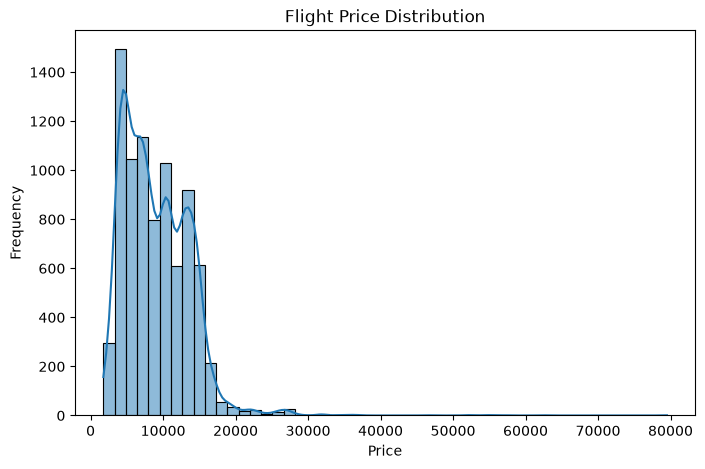

In [55]:
print("Price Skewness:", y_train.skew())

plt.figure(figsize=(8, 5))
sns.histplot(y_train, bins=50, kde=True)

plt.title("Flight Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

In [56]:
# Apply log transformation
y_train_log = np.log1p(y_train)

print("Original Price Skewness:", y_train.skew())
print("Log Transformed Skewness:", y_train_log.skew())

Original Price Skewness: 1.9537777569867354
Log Transformed Skewness: -0.23801011601526018


In [57]:
log_rf_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=None,
    random_state=42,
    n_jobs=2
)

log_rf_model.fit(X_train, y_train_log)

print("Log Transformed Random Forest Training Completed!")

Log Transformed Random Forest Training Completed!


In [58]:
# Predict log-transformed prices
log_pred = log_rf_model.predict(X_test)

# Convert predictions back to original prices
log_pred_price = np.expm1(log_pred)

# Compare actual and predicted prices
log_comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": log_pred_price
})

display(log_comparison.head(10))

,Actual Price,Predicted Price
0,17996,14701.818384
1,3873,3847.489709
2,4462,4220.378143
3,2228,4108.674879
4,4991,4549.713299
5,7670,7760.269944
6,14086,14017.153121
7,6386,6324.049982
8,6628,6255.433633
9,6934,6365.555815


In [59]:
log_mae = mean_absolute_error(y_test, log_pred_price)

log_rmse = np.sqrt(
    mean_squared_error(y_test, log_pred_price)
)

log_r2 = r2_score(y_test, log_pred_price)

print("Log Random Forest MAE:", log_mae)
print("Log Random Forest RMSE:", log_rmse)
print("Log Random Forest R2:", log_r2)

Log Random Forest MAE: 1146.7161010926786
Log Random Forest RMSE: 1948.3373151964781
Log Random Forest R2: 0.8179391857937615


In [60]:
print(train_clean.columns.tolist())

['Airline', 'Source', 'Destination', 'Total_Stops', 'Price', 'Journey_Day', 'Journey_Month', 'Dep_Hour', 'Dep_Minute', 'Arrival_Hour', 'Arrival_Minute', 'Duration_Hours']


In [61]:
print(train_df.columns.tolist())

['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route', 'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops', 'Additional_Info', 'Price']


In [62]:
# Convert date column into datetime format
train_df["Date_of_Journey"] = pd.to_datetime(
    train_df["Date_of_Journey"],
    dayfirst=True
)

# Extract weekday
train_df["Journey_Weekday"] = train_df["Date_of_Journey"].dt.dayofweek

display(
    train_df[["Date_of_Journey", "Journey_Weekday"]].head()
)

,Date_of_Journey,Journey_Weekday
0,2019-03-24,6
1,2019-05-01,2
2,2019-06-09,6
3,2019-05-12,6
4,2019-03-01,4


In [63]:
train_clean["Journey_Weekday"] = train_df.loc[
    train_clean.index, "Journey_Weekday"
]

print("Updated Shape:", train_clean.shape)

display(train_clean.head())

Updated Shape: (10462, 13)


,Airline,Source,Destination,Total_Stops,Price,Journey_Day,Journey_Month,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Hours,Journey_Weekday
0,IndiGo,Banglore,New Delhi,0,3897,24,3,22,20,1,10,2.833333,6
1,Air India,Kolkata,Banglore,2,7662,1,5,5,50,13,15,7.416667,2
2,Jet Airways,Delhi,Cochin,2,13882,9,6,9,25,4,25,19.000000,6
3,IndiGo,Kolkata,Banglore,1,6218,12,5,18,5,23,30,5.416667,6
4,IndiGo,Banglore,New Delhi,1,13302,1,3,16,50,21,35,4.750000,4


In [64]:
train_encoded = pd.get_dummies(
    train_clean,
    columns=["Airline", "Source", "Destination"],
    drop_first=True,
    dtype=int
)

print("Before Encoding:", train_clean.shape)
print("After Encoding:", train_encoded.shape)

display(train_encoded.head())

Before Encoding: (10462, 13)
After Encoding: (10462, 30)


,Total_Stops,Price,Journey_Day,Journey_Month,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Hours,Journey_Weekday,...,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,3897,24,3,22,20,1,10,2.833333,6,...,0,0,0,0,0,0,0,0,0,1
1,2,7662,1,5,5,50,13,15,7.416667,2,...,0,0,0,1,0,0,0,0,0,0
2,2,13882,9,6,9,25,4,25,19.000000,6,...,0,0,1,0,0,1,0,0,0,0
3,1,6218,12,5,18,5,23,30,5.416667,6,...,0,0,0,1,0,0,0,0,0,0
4,1,13302,1,3,16,50,21,35,4.750000,4,...,0,0,0,0,0,0,0,0,0,1


In [65]:
X_new = train_encoded.drop("Price", axis=1)
y_new = train_encoded["Price"]

print("Features Shape:", X_new.shape)
print("Target Shape:", y_new.shape)

Features Shape: (10462, 29)
Target Shape: (10462,)


In [66]:
from sklearn.model_selection import train_test_split

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new,
    y_new,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train_new.shape)
print("X_test:", X_test_new.shape)
print("y_train:", y_train_new.shape)
print("y_test:", y_test_new.shape)

X_train: (8369, 29)
X_test: (2093, 29)
y_train: (8369,)
y_test: (2093,)


In [67]:
rf_model_new = RandomForestRegressor(
    n_estimators=150,
    random_state=42,
    n_jobs=2
)

rf_model_new.fit(X_train_new, y_train_new)

print("Updated Random Forest Training Completed!")

Updated Random Forest Training Completed!


In [68]:
y_pred_new = rf_model_new.predict(X_test_new)

comparison_new = pd.DataFrame({
    "Actual Price": y_test_new.values,
    "Predicted Price": y_pred_new
})

display(comparison_new.head(10))

,Actual Price,Predicted Price
0,17996,14718.106667
1,3873,3848.446667
2,4462,4262.495556
3,2228,4559.162889
4,4991,4621.797556
5,7670,7720.486667
6,14086,14483.834889
7,6386,6298.940000
8,6628,6262.733333
9,6934,6528.800833


In [69]:
mae_new = mean_absolute_error(y_test_new, y_pred_new)

rmse_new = np.sqrt(
    mean_squared_error(y_test_new, y_pred_new)
)

r2_new = r2_score(y_test_new, y_pred_new)

print("Updated Random Forest MAE:", mae_new)
print("Updated Random Forest RMSE:", rmse_new)
print("Updated Random Forest R2:", r2_new)

Updated Random Forest MAE: 1182.2991585898574
Updated Random Forest RMSE: 1985.5276626830268
Updated Random Forest R2: 0.8109224056398294


In [70]:
feature_importance_new = pd.DataFrame({
    "Feature": X_train_new.columns,
    "Importance": rf_model_new.feature_importances_
})

feature_importance_new = feature_importance_new.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_new)

,Feature,Importance
7,Duration_Hours,0.456242
1,Journey_Day,0.112817
13,Airline_Jet Airways Business,0.076498
12,Airline_Jet Airways,0.059663
2,Journey_Month,0.056263
5,Arrival_Hour,0.033223
0,Total_Stops,0.029511
3,Dep_Hour,0.027070
4,Dep_Minute,0.025363
8,Journey_Weekday,0.024737


In [71]:
from sklearn.ensemble import ExtraTreesRegressor

et_model = ExtraTreesRegressor(
    n_estimators=150,
    random_state=42,
    n_jobs=2
)

et_model.fit(X_train_new, y_train_new)

print("Extra Trees Training Completed!")

Extra Trees Training Completed!


In [72]:
et_pred = et_model.predict(X_test_new)

et_comparison = pd.DataFrame({
    "Actual Price": y_test_new.values,
    "Predicted Price": et_pred
})

display(et_comparison.head(10))

,Actual Price,Predicted Price
0,17996,14710.683333
1,3873,3841.000000
2,4462,4280.980000
3,2228,4945.066667
4,4991,4885.000000
5,7670,7825.940000
6,14086,14528.520000
7,6386,6275.300000
8,6628,6225.186667
9,6934,6601.073333


In [73]:
et_mae = mean_absolute_error(y_test_new, et_pred)

et_rmse = np.sqrt(
    mean_squared_error(y_test_new, et_pred)
)

et_r2 = r2_score(y_test_new, et_pred)

print("Extra Trees MAE:", et_mae)
print("Extra Trees RMSE:", et_rmse)
print("Extra Trees R2:", et_r2)

Extra Trees MAE: 1231.0003795721188
Extra Trees RMSE: 2131.974573528835
Extra Trees R2: 0.7820021423318166


In [74]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

advanced_params = {
    "n_estimators": [100, 150, 200, 250],
    "max_depth": [10, 15, 20, 25, 30, None],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [1, 2, 3, 4],
    "max_features": ["sqrt", 0.5, 0.7, 1.0],
    "bootstrap": [True, False]
}

print("Advanced Parameter Search Space Ready!")

Advanced Parameter Search Space Ready!


In [75]:
advanced_rf = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),
    param_distributions=advanced_params,
    n_iter=15,
    cv=3,
    scoring="r2",
    random_state=42,
    n_jobs=2,
    verbose=1
)

print("Advanced Randomized Search Ready!")

Advanced Randomized Search Ready!


In [76]:
advanced_rf.fit(X_train, y_train)

print("Advanced Hyperparameter Tuning Completed!")

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Advanced Hyperparameter Tuning Completed!


In [77]:
print("Best Parameters:")
print(advanced_rf.best_params_)

print("\nBest Cross Validation R2:")
print(advanced_rf.best_score_)

Best Parameters:
{'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 15, 'bootstrap': True}

Best Cross Validation R2:
0.8232367150347542


In [78]:
best_advanced_rf = advanced_rf.best_estimator_

advanced_pred = best_advanced_rf.predict(X_test)

advanced_mae = mean_absolute_error(y_test, advanced_pred)

advanced_rmse = np.sqrt(
    mean_squared_error(y_test, advanced_pred)
)

advanced_r2 = r2_score(y_test, advanced_pred)

print("Advanced Random Forest MAE:", advanced_mae)
print("Advanced Random Forest RMSE:", advanced_rmse)
print("Advanced Random Forest R2:", advanced_r2)

Advanced Random Forest MAE: 1156.006311648166
Advanced Random Forest RMSE: 1856.7218705582231
Advanced Random Forest R2: 0.8346584936273572


In [79]:
print("99th Percentile:", y_train.quantile(0.99))
print("Maximum Price:", y_train.max())

99th Percentile: 22270.0
Maximum Price: 79512


In [80]:
# Calculate 99th percentile
upper_limit = y_train.quantile(0.99)

# Cap extreme training prices
y_train_capped = y_train.clip(upper=upper_limit)

print("Original Maximum:", y_train.max())
print("Capped Maximum:", y_train_capped.max())

print("Original Shape:", y_train.shape)
print("Capped Shape:", y_train_capped.shape)

Original Maximum: 79512
Capped Maximum: 22270
Original Shape: (8369,)
Capped Shape: (8369,)


In [81]:
rf_capped = RandomForestRegressor(
    n_estimators=150,
    random_state=42,
    n_jobs=2
)

rf_capped.fit(X_train, y_train_capped)

print("Capped Random Forest Training Completed!")

Capped Random Forest Training Completed!


In [82]:
capped_pred = rf_capped.predict(X_test)

capped_comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": capped_pred
})

display(capped_comparison.head(10))

,Actual Price,Predicted Price
0,17996,14782.826778
1,3873,3841.520000
2,4462,4241.975556
3,2228,4581.082222
4,4991,4544.205778
5,7670,7566.506667
6,14086,14377.181111
7,6386,6372.746667
8,6628,6264.700000
9,6934,6485.690000


In [83]:
capped_mae = mean_absolute_error(y_test, capped_pred)

capped_rmse = np.sqrt(
    mean_squared_error(y_test, capped_pred)
)

capped_r2 = r2_score(y_test, capped_pred)

print("Capped Random Forest MAE:", capped_mae)
print("Capped Random Forest RMSE:", capped_rmse)
print("Capped Random Forest R2:", capped_r2)

Capped Random Forest MAE: 1195.1689514131351
Capped Random Forest RMSE: 2091.1315992601494
Capped Random Forest R2: 0.7902746569797234


In [84]:
from sklearn.model_selection import cross_val_score

rf_cv = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    n_jobs=2
)

print("5-Fold CV Scores:", rf_cv)
print("Average CV R2:", rf_cv.mean())
print("Standard Deviation:", rf_cv.std())

5-Fold CV Scores: [0.79164044 0.82694707 0.83700973 0.82468673 0.80986236]
Average CV R2: 0.8180292682199971
Standard Deviation: 0.015793516370877173


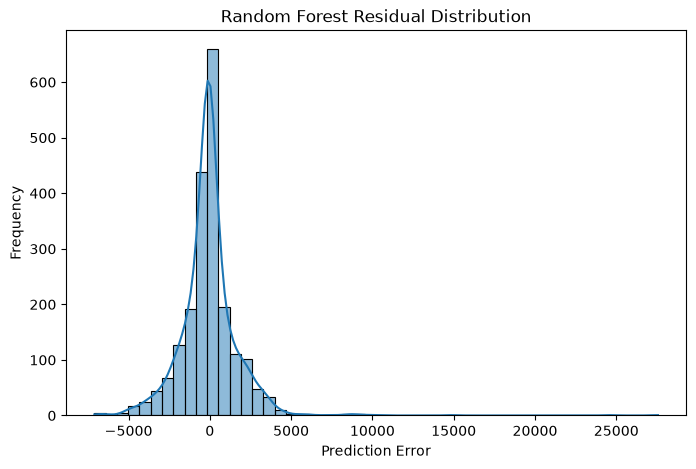

In [85]:
# Calculate prediction errors
residuals = y_test - rf_pred

# Plot residual distribution
plt.figure(figsize=(8, 5))

sns.histplot(residuals, bins=50, kde=True)

plt.title("Random Forest Residual Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()

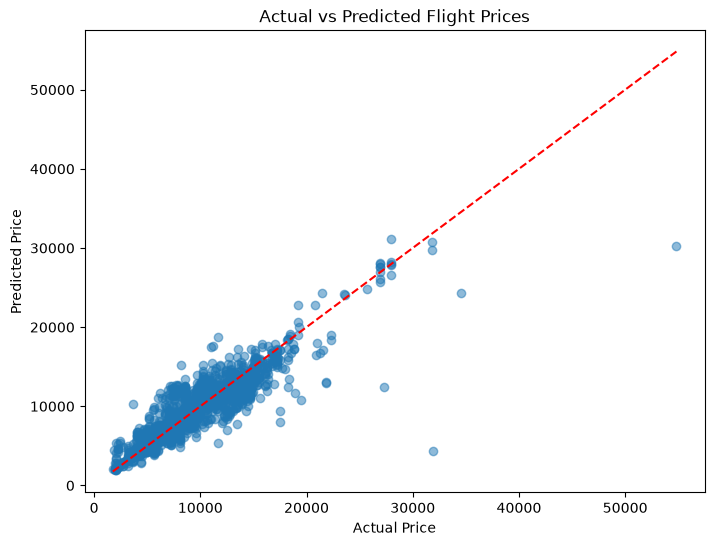

In [86]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.title("Actual vs Predicted Flight Prices")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.show()

In [87]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

hgb_model.fit(X_train, y_train)

print("HistGradientBoosting Training Completed!")

HistGradientBoosting Training Completed!


In [88]:
hgb_pred = hgb_model.predict(X_test)

hgb_comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": hgb_pred
})

display(hgb_comparison.head(10))

,Actual Price,Predicted Price
0,17996,15008.274941
1,3873,3911.306885
2,4462,4303.995261
3,2228,4386.698044
4,4991,4117.923034
5,7670,8754.761212
6,14086,17703.317224
7,6386,5914.160752
8,6628,6902.463693
9,6934,5922.252916


In [89]:
hgb_mae = mean_absolute_error(y_test, hgb_pred)

hgb_rmse = np.sqrt(
    mean_squared_error(y_test, hgb_pred)
)

hgb_r2 = r2_score(y_test, hgb_pred)

print("HistGradientBoosting MAE:", hgb_mae)
print("HistGradientBoosting RMSE:", hgb_rmse)
print("HistGradientBoosting R2:", hgb_r2)

HistGradientBoosting MAE: 1198.2363270290966
HistGradientBoosting RMSE: 1877.4492177194863
HistGradientBoosting R2: 0.8309463384931312


In [90]:
try:
    import xgboost as xgb
    print("XGBoost Version:", xgb.__version__)
except ImportError:
    print("XGBoost is not installed.")

XGBoost Version: 3.4.1


In [91]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=2
)

xgb_model.fit(X_train, y_train)

print("XGBoost Training Completed!")

XGBoost Training Completed!


In [92]:
xgb_pred = xgb_model.predict(X_test)

xgb_comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": xgb_pred
})

display(xgb_comparison.head(10))

,Actual Price,Predicted Price
0,17996,14609.541016
1,3873,3783.169922
2,4462,4578.098633
3,2228,4566.622559
4,4991,4154.840332
5,7670,9288.100586
6,14086,16527.912109
7,6386,6588.485352
8,6628,7284.640625
9,6934,6143.314941


In [93]:
xgb_mae = mean_absolute_error(y_test, xgb_pred)

xgb_rmse = np.sqrt(
    mean_squared_error(y_test, xgb_pred)
)

xgb_r2 = r2_score(y_test, xgb_pred)

print("XGBoost MAE:", xgb_mae)
print("XGBoost RMSE:", xgb_rmse)
print("XGBoost R2:", xgb_r2)

XGBoost MAE: 1227.2537841796875
XGBoost RMSE: 1877.175138339521
XGBoost R2: 0.8309956789016724


In [94]:
xgb_params = {
    "n_estimators": [200, 300, 400, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [3, 4, 5, 6, 8],
    "min_child_weight": [1, 3, 5, 7],
    "gamma": [0, 0.1, 0.3, 0.5, 1],
    "subsample": [0.6, 0.7, 0.8, 0.9],
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9],
    "reg_alpha": [0, 0.01, 0.1, 0.5, 1],
    "reg_lambda": [1, 3, 5, 10]
}

print("Advanced XGBoost Parameter Space Ready!")

Advanced XGBoost Parameter Space Ready!


In [95]:
from sklearn.model_selection import RandomizedSearchCV

xgb_random = RandomizedSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    ),
    param_distributions=xgb_params,
    n_iter=20,
    cv=3,
    scoring="r2",
    random_state=42,
    n_jobs=2,
    verbose=1
)

print("XGBoost Randomized Search Ready!")

XGBoost Randomized Search Ready!


In [96]:
xgb_random.fit(X_train, y_train)

print("Advanced XGBoost Tuning Completed!")

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Advanced XGBoost Tuning Completed!


In [97]:
print("Best XGBoost Parameters:")
print(xgb_random.best_params_)

print("\nBest Cross Validation R2:")
print(xgb_random.best_score_)

Best XGBoost Parameters:
{'subsample': 0.9, 'reg_lambda': 3, 'reg_alpha': 0.5, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.03, 'gamma': 0.3, 'colsample_bytree': 0.7}

Best Cross Validation R2:
0.8338020841280619


In [98]:
# Get best tuned XGBoost model
best_xgb_model = xgb_random.best_estimator_

# Predict on test data
xgb_tuned_pred = best_xgb_model.predict(X_test)

# Calculate evaluation metrics
xgb_tuned_mae = mean_absolute_error(y_test, xgb_tuned_pred)

xgb_tuned_rmse = np.sqrt(
    mean_squared_error(y_test, xgb_tuned_pred)
)

xgb_tuned_r2 = r2_score(y_test, xgb_tuned_pred)

print("Tuned XGBoost MAE:", xgb_tuned_mae)
print("Tuned XGBoost RMSE:", xgb_tuned_rmse)
print("Tuned XGBoost R2:", xgb_tuned_r2)

Tuned XGBoost MAE: 1104.2332763671875
Tuned XGBoost RMSE: 1826.6348841517288
Tuned XGBoost R2: 0.8399735689163208


In [99]:
xgb_cv_scores = cross_val_score(
    best_xgb_model,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    n_jobs=2
)

print("XGBoost 5-Fold CV Scores:", xgb_cv_scores)
print("Average CV R2:", xgb_cv_scores.mean())
print("Standard Deviation:", xgb_cv_scores.std())

XGBoost 5-Fold CV Scores: [0.85314798 0.84327871 0.87208784 0.82938457 0.83033687]
Average CV R2: 0.8456471920013428
Standard Deviation: 0.015873615163043878


In [100]:
final_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Tuned XGBoost"
    ],
    "MAE": [
        rf_mae,
        xgb_tuned_mae
    ],
    "RMSE": [
        rf_rmse,
        xgb_tuned_rmse
    ],
    "R2 Score": [
        rf_r2,
        xgb_tuned_r2
    ]
})

display(
    final_comparison
    .sort_values(by="R2 Score", ascending=False)
    .reset_index(drop=True)
)

,Model,MAE,RMSE,R2 Score
0,Tuned XGBoost,1104.233276,1826.634884,0.839974
1,Random Forest,1112.898037,1843.737023,0.836963


In [101]:
# Create weekend feature
train_clean["Is_Weekend"] = train_clean["Journey_Weekday"].isin([5, 6]).astype(int)

print(train_clean[["Journey_Weekday", "Is_Weekend"]].head(10))

   Journey_Weekday  Is_Weekend
0                6           1
1                2           0
2                6           1
3                6           1
4                4           0
5                0           0
6                1           0
7                4           0
8                1           0
9                0           0


In [102]:
def get_time_category(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"


train_clean["Dep_Time_Category"] = train_clean["Dep_Hour"].apply(
    get_time_category
)

print(train_clean["Dep_Time_Category"].value_counts())

Dep_Time_Category
Morning      4806
Evening      2323
Afternoon    1874
Night        1459
Name: count, dtype: int64


In [103]:
train_clean["Arrival_Time_Category"] = train_clean["Arrival_Hour"].apply(
    get_time_category
)

print(train_clean["Arrival_Time_Category"].value_counts())

Arrival_Time_Category
Night        3562
Evening      2631
Morning      2259
Afternoon    2010
Name: count, dtype: int64


In [104]:
print("Updated Shape:", train_clean.shape)

display(
    train_clean[
        [
            "Journey_Weekday",
            "Is_Weekend",
            "Dep_Time_Category",
            "Arrival_Time_Category"
        ]
    ].head()
)

Updated Shape: (10462, 16)


,Journey_Weekday,Is_Weekend,Dep_Time_Category,Arrival_Time_Category
0,6,1,Night,Night
1,2,0,Morning,Afternoon
2,6,1,Morning,Night
3,6,1,Evening,Night
4,4,0,Afternoon,Night


In [105]:
# Separate features and target
X_new = train_clean.drop("Price", axis=1)
y_new = train_clean["Price"]

# Identify categorical columns
cat_cols = X_new.select_dtypes(include="object").columns.tolist()

print("Categorical Columns:", cat_cols)

# One-Hot Encoding
X_new_encoded = pd.get_dummies(
    X_new,
    columns=cat_cols,
    drop_first=True,
    dtype=int
)

print("\nBefore Encoding:", X_new.shape)
print("After Encoding:", X_new_encoded.shape)

display(X_new_encoded.head())

Categorical Columns: ['Airline', 'Source', 'Destination', 'Dep_Time_Category', 'Arrival_Time_Category']

Before Encoding: (10462, 15)
After Encoding: (10462, 36)


C:\Users\Mrinal Dutta\AppData\Local\Temp\ipykernel_16980\2533793773.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_new.select_dtypes(include="object").columns.tolist()


,Total_Stops,Journey_Day,Journey_Month,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Hours,Journey_Weekday,Is_Weekend,...,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi,Dep_Time_Category_Evening,Dep_Time_Category_Morning,Dep_Time_Category_Night,Arrival_Time_Category_Evening,Arrival_Time_Category_Morning,Arrival_Time_Category_Night
0,0,24,3,22,20,1,10,2.833333,6,1,...,0,0,0,1,0,0,1,0,0,1
1,2,1,5,5,50,13,15,7.416667,2,0,...,0,0,0,0,0,1,0,0,0,0
2,2,9,6,9,25,4,25,19.000000,6,1,...,0,0,0,0,0,1,0,0,0,1
3,1,12,5,18,5,23,30,5.416667,6,1,...,0,0,0,0,1,0,0,0,0,1
4,1,1,3,16,50,21,35,4.750000,4,0,...,0,0,0,1,0,0,0,0,0,1


In [106]:
from sklearn.model_selection import train_test_split

X_new = X_new_encoded
y_new = train_clean["Price"]

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new,
    y_new,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train_new.shape)
print("X_test:", X_test_new.shape)
print("y_train:", y_train_new.shape)
print("y_test:", y_test_new.shape)

X_train: (8369, 36)
X_test: (2093, 36)
y_train: (8369,)
y_test: (2093,)


In [107]:
print("Total Features:", X_train_new.shape[1])

print("Training Columns:")
print(X_train_new.columns.tolist())

print("\nMissing Values:", X_train_new.isnull().sum().sum())

Total Features: 36
Training Columns:
['Total_Stops', 'Journey_Day', 'Journey_Month', 'Dep_Hour', 'Dep_Minute', 'Arrival_Hour', 'Arrival_Minute', 'Duration_Hours', 'Journey_Weekday', 'Is_Weekend', 'Airline_Air India', 'Airline_GoAir', 'Airline_IndiGo', 'Airline_Jet Airways', 'Airline_Jet Airways Business', 'Airline_Multiple carriers', 'Airline_Multiple carriers Premium economy', 'Airline_SpiceJet', 'Airline_Trujet', 'Airline_Vistara', 'Airline_Vistara Premium economy', 'Source_Chennai', 'Source_Delhi', 'Source_Kolkata', 'Source_Mumbai', 'Destination_Cochin', 'Destination_Delhi', 'Destination_Hyderabad', 'Destination_Kolkata', 'Destination_New Delhi', 'Dep_Time_Category_Evening', 'Dep_Time_Category_Morning', 'Dep_Time_Category_Night', 'Arrival_Time_Category_Evening', 'Arrival_Time_Category_Morning', 'Arrival_Time_Category_Night']

Missing Values: 0


In [108]:
from xgboost import XGBRegressor

xgb_feature_model = XGBRegressor(
    **xgb_random.best_params_,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=2
)

xgb_feature_model.fit(X_train_new, y_train_new)

print("Feature Engineered XGBoost Training Completed!")

Feature Engineered XGBoost Training Completed!


In [109]:
xgb_feature_pred = xgb_feature_model.predict(X_test_new)

feature_comparison = pd.DataFrame({
    "Actual Price": y_test_new.values,
    "Predicted Price": xgb_feature_pred
})

display(feature_comparison.head(10))

,Actual Price,Predicted Price
0,17996,15327.122070
1,3873,3771.643799
2,4462,4143.622559
3,2228,4678.273926
4,4991,4425.651367
5,7670,8086.647461
6,14086,19654.966797
7,6386,5962.079102
8,6628,6827.104980
9,6934,6354.179199


In [110]:
xgb_feature_mae = mean_absolute_error(
    y_test_new, xgb_feature_pred
)

xgb_feature_rmse = np.sqrt(
    mean_squared_error(y_test_new, xgb_feature_pred)
)

xgb_feature_r2 = r2_score(
    y_test_new, xgb_feature_pred
)

print("Feature Engineered XGBoost MAE:", xgb_feature_mae)
print("Feature Engineered XGBoost RMSE:", xgb_feature_rmse)
print("Feature Engineered XGBoost R2:", xgb_feature_r2)

Feature Engineered XGBoost MAE: 1114.9521484375
Feature Engineered XGBoost RMSE: 1834.623122060768
Feature Engineered XGBoost R2: 0.8385708332061768


In [111]:
import numpy as np

cyclic_df = train_clean.copy()

# Cyclical encoding for departure hour
cyclic_df["Dep_Hour_Sin"] = np.sin(
    2 * np.pi * cyclic_df["Dep_Hour"] / 24
)

cyclic_df["Dep_Hour_Cos"] = np.cos(
    2 * np.pi * cyclic_df["Dep_Hour"] / 24
)

# Cyclical encoding for arrival hour
cyclic_df["Arrival_Hour_Sin"] = np.sin(
    2 * np.pi * cyclic_df["Arrival_Hour"] / 24
)

cyclic_df["Arrival_Hour_Cos"] = np.cos(
    2 * np.pi * cyclic_df["Arrival_Hour"] / 24
)

display(
    cyclic_df[
        [
            "Dep_Hour",
            "Dep_Hour_Sin",
            "Dep_Hour_Cos",
            "Arrival_Hour",
            "Arrival_Hour_Sin",
            "Arrival_Hour_Cos"
        ]
    ].head()
)

,Dep_Hour,Dep_Hour_Sin,Dep_Hour_Cos,Arrival_Hour,Arrival_Hour_Sin,Arrival_Hour_Cos
0,22,-0.500000,8.660254e-01,1,0.258819,0.965926
1,5,0.965926,2.588190e-01,13,-0.258819,-0.965926
2,9,0.707107,-7.071068e-01,4,0.866025,0.500000
3,18,-1.000000,-1.836970e-16,23,-0.258819,0.965926
4,16,-0.866025,-5.000000e-01,21,-0.707107,0.707107


In [112]:
# Cyclical encoding for Journey Month

cyclic_df["Month_Sin"] = np.sin(
    2 * np.pi * cyclic_df["Journey_Month"] / 12
)

cyclic_df["Month_Cos"] = np.cos(
    2 * np.pi * cyclic_df["Journey_Month"] / 12
)

display(
    cyclic_df[
        [
            "Journey_Month",
            "Month_Sin",
            "Month_Cos"
        ]
    ].head(10)
)

,Journey_Month,Month_Sin,Month_Cos
0,3,1.000000e+00,6.123234e-17
1,5,5.000000e-01,-8.660254e-01
2,6,1.224647e-16,-1.000000e+00
3,5,5.000000e-01,-8.660254e-01
4,3,1.000000e+00,6.123234e-17
5,6,1.224647e-16,-1.000000e+00
6,3,1.000000e+00,6.123234e-17
7,3,1.000000e+00,6.123234e-17
8,3,1.000000e+00,6.123234e-17
9,5,5.000000e-01,-8.660254e-01


In [113]:
# Remove previous experimental features
cyclic_df = cyclic_df.drop(
    columns=[
        "Journey_Weekday",
        "Is_Weekend",
        "Dep_Time_Category",
        "Arrival_Time_Category"
    ]
)

# Drop original Price from features
X_cyclic = cyclic_df.drop("Price", axis=1)
y_cyclic = cyclic_df["Price"]

# Identify categorical columns
cat_cols = X_cyclic.select_dtypes(include="object").columns.tolist()

# One-Hot Encoding
X_cyclic_encoded = pd.get_dummies(
    X_cyclic,
    columns=cat_cols,
    drop_first=True,
    dtype=int
)

print("Before Encoding:", X_cyclic.shape)
print("After Encoding:", X_cyclic_encoded.shape)

display(X_cyclic_encoded.head())

Before Encoding: (10462, 17)
After Encoding: (10462, 34)


C:\Users\Mrinal Dutta\AppData\Local\Temp\ipykernel_16980\1611711267.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_cyclic.select_dtypes(include="object").columns.tolist()


,Total_Stops,Journey_Day,Journey_Month,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Hours,Dep_Hour_Sin,Dep_Hour_Cos,...,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,24,3,22,20,1,10,2.833333,-0.500000,8.660254e-01,...,0,0,0,0,0,0,0,0,0,1
1,2,1,5,5,50,13,15,7.416667,0.965926,2.588190e-01,...,0,0,0,1,0,0,0,0,0,0
2,2,9,6,9,25,4,25,19.000000,0.707107,-7.071068e-01,...,0,0,1,0,0,1,0,0,0,0
3,1,12,5,18,5,23,30,5.416667,-1.000000,-1.836970e-16,...,0,0,0,1,0,0,0,0,0,0
4,1,1,3,16,50,21,35,4.750000,-0.866025,-5.000000e-01,...,0,0,0,0,0,0,0,0,0,1


In [114]:
X_cyclic = X_cyclic_encoded
y_cyclic = cyclic_df["Price"]

X_train_cyclic, X_test_cyclic, y_train_cyclic, y_test_cyclic = train_test_split(
    X_cyclic,
    y_cyclic,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train_cyclic.shape)
print("X_test:", X_test_cyclic.shape)
print("y_train:", y_train_cyclic.shape)
print("y_test:", y_test_cyclic.shape)

X_train: (8369, 34)
X_test: (2093, 34)
y_train: (8369,)
y_test: (2093,)


In [115]:
xgb_cyclic_model = XGBRegressor(
    **xgb_random.best_params_,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=2
)

xgb_cyclic_model.fit(
    X_train_cyclic,
    y_train_cyclic
)

print("Cyclical XGBoost Training Completed!")

Cyclical XGBoost Training Completed!


In [116]:
xgb_cyclic_pred = xgb_cyclic_model.predict(X_test_cyclic)

cyclic_comparison = pd.DataFrame({
    "Actual Price": y_test_cyclic.values,
    "Predicted Price": xgb_cyclic_pred
})

display(cyclic_comparison.head(10))

,Actual Price,Predicted Price
0,17996,14755.577148
1,3873,3864.690918
2,4462,4348.136230
3,2228,4617.106934
4,4991,4330.156738
5,7670,8062.566406
6,14086,18864.945312
7,6386,6080.755859
8,6628,6886.754883
9,6934,6387.958496


In [117]:
cyclic_mae = mean_absolute_error(
    y_test_cyclic, xgb_cyclic_pred
)

cyclic_rmse = np.sqrt(
    mean_squared_error(y_test_cyclic, xgb_cyclic_pred)
)

cyclic_r2 = r2_score(
    y_test_cyclic, xgb_cyclic_pred
)

print("Cyclical XGBoost MAE:", cyclic_mae)
print("Cyclical XGBoost RMSE:", cyclic_rmse)
print("Cyclical XGBoost R2:", cyclic_r2)

Cyclical XGBoost MAE: 1109.7625732421875
Cyclical XGBoost RMSE: 1844.9370585469846
Cyclical XGBoost R2: 0.8367507457733154


In [118]:
try:
    import catboost
    print("CatBoost Version:", catboost.__version__)

except ImportError:
    print("CatBoost is not installed.")

CatBoost is not installed.


In [119]:
%pip install catboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
    --------------------------------------- 1.3/101.7 MB 8.4 MB/s eta 0:00:12
   - -------------------------------------- 3.9/101.7 MB 11.3 MB/s eta 0:00:09
   -- ------------------------------------- 6.0/101.7 MB 10.5 MB/s eta 0:00:10
   --- ------------------------------------ 7.9/101.7 MB 10.1 MB/s eta 0:00:10
   ---- ----------------------------------- 10.2/101.7 MB 10.2 MB/s eta 0:00:09
   ---- ----------------------------------- 12.6/101.7 MB 10.4 MB/s eta 0:00:09
   ----- ---------------------------------- 14.9/101.7 MB 10.5 MB/s eta 0:00:09
   ------ --------------------------------- 17.0/101.7 MB 10.3 MB/s eta 0:00:09
   ------- -------------------------------- 19.1/101.7 MB 10.3 MB/s eta 0:00:09
   -------- ------------------------------- 21.0/101.7 MB 10.1 MB/s eta 0:00:08
   -------- ------------------------------- 22.0/101.7 MB 9.7 MB/s eta 0:00:09
   --------- ------------------------------ 23.3/101.7 

In [120]:
import catboost

print("CatBoost Version:", catboost.__version__)

CatBoost Version: 1.2.10


In [121]:
from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split

cat_df = train_clean.copy()

X_cat = cat_df.drop("Price", axis=1)
y_cat = cat_df["Price"]

cat_features = X_cat.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Categorical Features:", cat_features)
print("Features Shape:", X_cat.shape)
print("Target Shape:", y_cat.shape)

Categorical Features: ['Airline', 'Source', 'Destination', 'Dep_Time_Category', 'Arrival_Time_Category']
Features Shape: (10462, 15)
Target Shape: (10462,)


In [122]:
X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(
    X_cat,
    y_cat,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train_cat.shape)
print("X_test:", X_test_cat.shape)
print("y_train:", y_train_cat.shape)
print("y_test:", y_test_cat.shape)

X_train: (8369, 15)
X_test: (2093, 15)
y_train: (8369,)
y_test: (2093,)


In [123]:
cat_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    eval_metric="RMSE",
    l2_leaf_reg=5,
    random_seed=42,
    verbose=100,
    early_stopping_rounds=100,
    thread_count=2
)

cat_model.fit(
    X_train_cat,
    y_train_cat,
    cat_features=cat_features,
    eval_set=(X_test_cat, y_test_cat),
    use_best_model=True
)

print("CatBoost Training Completed!")

0:	learn: 4505.9140024	test: 4431.9618710	best: 4431.9618710 (0)	total: 187ms	remaining: 3m 6s
100:	learn: 2019.7669566	test: 2135.0289603	best: 2135.0289603 (100)	total: 7.43s	remaining: 1m 6s
200:	learn: 1777.5511848	test: 1999.4948081	best: 1999.3587025 (198)	total: 14.6s	remaining: 57.9s
300:	learn: 1652.5528443	test: 1941.9980552	best: 1941.9980552 (300)	total: 21.9s	remaining: 50.8s
400:	learn: 1562.2436992	test: 1912.2983724	best: 1911.9852582 (398)	total: 29.1s	remaining: 43.4s
500:	learn: 1480.1934948	test: 1880.9530224	best: 1880.9530224 (500)	total: 36.4s	remaining: 36.3s
600:	learn: 1426.7190045	test: 1863.0063281	best: 1863.0063281 (600)	total: 43.9s	remaining: 29.2s
700:	learn: 1381.7177392	test: 1851.4493592	best: 1851.4053867 (683)	total: 51.5s	remaining: 22s
800:	learn: 1333.4470678	test: 1844.7108297	best: 1844.0640359 (784)	total: 59s	remaining: 14.7s
900:	learn: 1293.4556206	test: 1838.8802897	best: 1838.8802897 (900)	total: 1m 6s	remaining: 7.32s
999:	learn: 1259.0

In [124]:
cat_pred = cat_model.predict(X_test_cat)

cat_comparison = pd.DataFrame({
    "Actual Price": y_test_cat.values,
    "Predicted Price": cat_pred
})

display(cat_comparison.head(10))

,Actual Price,Predicted Price
0,17996,15067.060254
1,3873,3996.013411
2,4462,4465.714262
3,2228,4394.356544
4,4991,4401.582985
5,7670,8870.884083
6,14086,17545.503533
7,6386,6004.877824
8,6628,6636.092309
9,6934,6355.449941


In [125]:
cat_mae = mean_absolute_error(y_test_cat, cat_pred)

cat_rmse = np.sqrt(
    mean_squared_error(y_test_cat, cat_pred)
)

cat_r2 = r2_score(y_test_cat, cat_pred)

print("CatBoost MAE:", cat_mae)
print("CatBoost RMSE:", cat_rmse)
print("CatBoost R2:", cat_r2)

CatBoost MAE: 1168.3072616534184
CatBoost RMSE: 1835.8515285702642
CatBoost R2: 0.8383546206358753


In [126]:
original_features = [
    "Airline",
    "Source",
    "Destination",
    "Total_Stops",
    "Journey_Day",
    "Journey_Month",
    "Dep_Hour",
    "Dep_Minute",
    "Arrival_Hour",
    "Arrival_Minute",
    "Duration_Hours",
    "Journey_Weekday"
]

print("Original Features:")
print(original_features)

print("\nMissing Columns:")
print(set(original_features) - set(train_clean.columns))

Original Features:
['Airline', 'Source', 'Destination', 'Total_Stops', 'Journey_Day', 'Journey_Month', 'Dep_Hour', 'Dep_Minute', 'Arrival_Hour', 'Arrival_Minute', 'Duration_Hours', 'Journey_Weekday']

Missing Columns:
set()


In [127]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

# Select original features
X = train_clean[original_features]
y = train_clean["Price"]

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical Features:", categorical_cols)
print("Numerical Features:", numerical_cols)

Categorical Features: ['Airline', 'Source', 'Destination']
Numerical Features: ['Total_Stops', 'Journey_Day', 'Journey_Month', 'Dep_Hour', 'Dep_Minute', 'Arrival_Hour', 'Arrival_Minute', 'Duration_Hours', 'Journey_Weekday']


C:\Users\Mrinal Dutta\AppData\Local\Temp\ipykernel_16980\914836594.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()


In [128]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ),
        (
            "numerical",
            "passthrough",
            numerical_cols
        )
    ]
)

print("Preprocessor Created Successfully!")

Preprocessor Created Successfully!


In [129]:
final_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            XGBRegressor(
                **xgb_random.best_params_,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=2
            )
        )
    ]
)

print("Complete XGBoost Pipeline Created Successfully!")

Complete XGBoost Pipeline Created Successfully!


In [130]:
X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

final_pipeline.fit(X_train_final, y_train_final)

print("Final XGBoost Pipeline Training Completed!")

Final XGBoost Pipeline Training Completed!


In [131]:
# Predictions
final_pred = final_pipeline.predict(X_test_final)

# Evaluation metrics
final_mae = mean_absolute_error(y_test_final, final_pred)

final_rmse = np.sqrt(
    mean_squared_error(y_test_final, final_pred)
)

final_r2 = r2_score(y_test_final, final_pred)

print("Final Pipeline MAE:", final_mae)
print("Final Pipeline RMSE:", final_rmse)
print("Final Pipeline R2:", final_r2)

Final Pipeline MAE: 1118.568115234375
Final Pipeline RMSE: 1847.5968851456748
Final Pipeline R2: 0.8362796306610107


In [132]:
from sklearn.model_selection import cross_val_score

pipeline_cv = cross_val_score(
    final_pipeline,
    X_train_final,
    y_train_final,
    cv=5,
    scoring="r2",
    n_jobs=2
)

print("Pipeline CV Scores:", pipeline_cv)
print("Average CV R2:", pipeline_cv.mean())
print("Standard Deviation:", pipeline_cv.std())

Pipeline CV Scores: [0.85341108 0.84273541 0.87076581 0.82509726 0.8242476 ]
Average CV R2: 0.8432514309883118
Standard Deviation: 0.01761388639294362


In [133]:
# Train final pipeline on complete dataset
final_pipeline.fit(X, y)

print("Final Model Training Completed on Full Dataset!")

Final Model Training Completed on Full Dataset!


In [134]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_pipeline,
    "../models/flight_price_prediction_pipeline.pkl"
)

print("Final Pipeline Saved Successfully!")

Final Pipeline Saved Successfully!


In [135]:
print(os.path.abspath("../models/flight_price_prediction_pipeline.pkl"))

C:\Users\Mrinal Dutta\Flight_Price_Prediction\models\flight_price_prediction_pipeline.pkl


In [136]:
loaded_model = joblib.load(
    "../models/flight_price_prediction_pipeline.pkl"
)

print("Saved Model Loaded Successfully!")

Saved Model Loaded Successfully!


In [137]:
print(train_clean[original_features].dtypes)

Airline                str
Source                 str
Destination            str
Total_Stops          int64
Journey_Day          int32
Journey_Month        int32
Dep_Hour             int32
Dep_Minute           int32
Arrival_Hour         int32
Arrival_Minute       int32
Duration_Hours     float64
Journey_Weekday      int32
dtype: object


In [138]:
sample_flight = pd.DataFrame([{
    "Airline": "IndiGo",
    "Source": "Delhi",
    "Destination": "Mumbai",
    "Total_Stops": 1,
    "Journey_Day": 15,
    "Journey_Month": 6,
    "Dep_Hour": 10,
    "Dep_Minute": 30,
    "Arrival_Hour": 13,
    "Arrival_Minute": 0,
    "Duration_Hours": 2.5,
    "Journey_Weekday": 0
}])

display(sample_flight)

,Airline,Source,Destination,Total_Stops,Journey_Day,Journey_Month,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Hours,Journey_Weekday
0,IndiGo,Delhi,Mumbai,1,15,6,10,30,13,0,2.5,0


In [139]:
predicted_price = loaded_model.predict(sample_flight)

print("Flight Details:")
display(sample_flight)

print("Predicted Flight Price: ₹", round(predicted_price[0], 2))

Flight Details:


,Airline,Source,Destination,Total_Stops,Journey_Day,Journey_Month,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Hours,Journey_Weekday
0,IndiGo,Delhi,Mumbai,1,15,6,10,30,13,0,2.5,0


Predicted Flight Price: ₹ 4871.52
